# House Price Prediction — California Housing

Hi, I am Emon. In this notebook I try to guess house prices from real data.
The data is the California Housing dataset — 20,640 houses from the 1990 US Census.
Target: median house value in a block (in $100,000s, so 2.0 means $200,000).

I will do it step by step: load the data, look at it, make a few new features,
train 3 models, and check which one is best. No fake numbers — whatever the
models give, I will write that down.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
plt.style.use("ggplot")
%matplotlib inline

## 1. Load the real data

`fetch_california_housing` downloads the real dataset. I save a copy in `data/`
so I can look at it again later. First check: how many rows, and is anything missing?

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.to_csv("data/california_housing.csv", index=False)
print("Rows:", len(df))
print(df.head())
print(df.describe().round(2))
print("Missing values:")
print(df.isna().sum())

Rows: 20640
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
count  20640.00  20640.00  20640.00   20640.00    20640.00  20640.00   
mean       3.87     28.64      5.43       1.10     1425.48      3.07   
std        1.90     12.59      2.47       0.47     1132.46     10.39   
min        0.50      1.00      0.85       0.33        3.00      0.69   
25%

## 2. Make a few new features

Raw columns are fine, but a few ratios make more sense:
- rooms per household = average rooms / average people in a house
- bedrooms ratio = bedrooms / rooms
- population per household = population / people in a house

If a division gives infinity, I fill it with the median value.

In [3]:
df["rooms_per_household"] = df["AveRooms"] / df["AveOccup"]
df["bedrooms_ratio"] = df["AveBedrms"] / df["AveRooms"]
df["population_per_household"] = df["Population"] / df["AveOccup"]
df = df.replace([np.inf, -np.inf], np.nan).fillna(df.median(numeric_only=True))
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population",
            "AveOccup", "Latitude", "Longitude",
            "rooms_per_household", "bedrooms_ratio", "population_per_household"]
X = df[features]
y = df["MedHouseVal"]
print("Features:", features)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'rooms_per_household', 'bedrooms_ratio', 'population_per_household']


## 3. Split the data and scale it

80% for training, 20% for testing. I scale the numbers for Linear Regression
(tree models do not need scaling, but it does not hurt them).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 16512  Test: 4128


## 4. Train 3 models and compare them

- Linear Regression — the simple one
- Random Forest — many decision trees together
- Gradient Boosting — trees that fix each other's mistakes

I check R² (higher is better, 1.0 is perfect), MAE and RMSE (lower is better).
MAE is in $100,000s, so MAE 0.33 means about $33,000 average error.
I also do 5-fold cross-validation, so the score is not just luck on one split.

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows = []
for name, model in models.items():
    if name == "Linear Regression":
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        cv = cross_val_score(model, X_train_s, y_train, cv=5, scoring="r2")
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        cv = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    rows.append({"Model": name, "R2": round(r2, 4), "MAE": round(mae, 4),
                 "RMSE": round(rmse, 4), "CV_R2": round(cv.mean(), 4)})
    print(f"{name}: R2={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}  CV R2={cv.mean():.4f}±{cv.std():.4f}")
results = pd.DataFrame(rows)
results

Linear Regression: R2=0.6535  MAE=0.4874  RMSE=0.6738  CV R2=0.6593±0.0195


Random Forest: R2=0.8065  MAE=0.3280  RMSE=0.5035  CV R2=0.8039±0.0052


Gradient Boosting: R2=0.7788  MAE=0.3668  RMSE=0.5384  CV R2=0.7897±0.0026


,Model,R2,MAE,RMSE,CV_R2
0,Linear Regression,0.6535,0.4874,0.6738,0.6593
1,Random Forest,0.8065,0.3280,0.5035,0.8039
2,Gradient Boosting,0.7788,0.3668,0.5384,0.7897


## 5. Look at the data — charts

First, how are prices spread out? And does income matter?

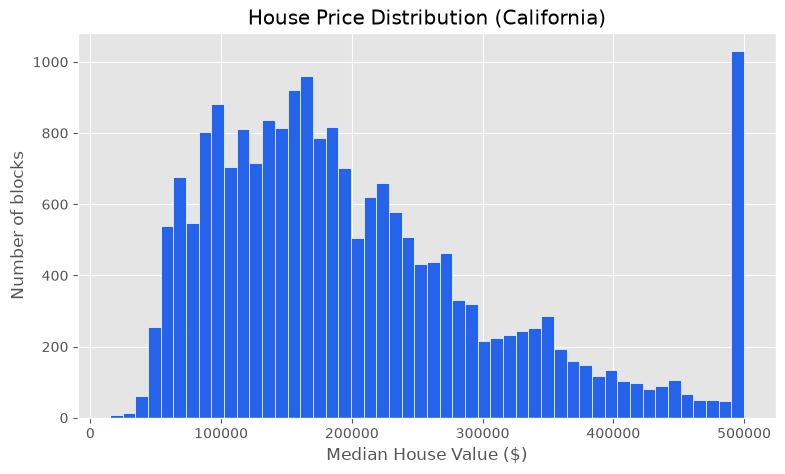

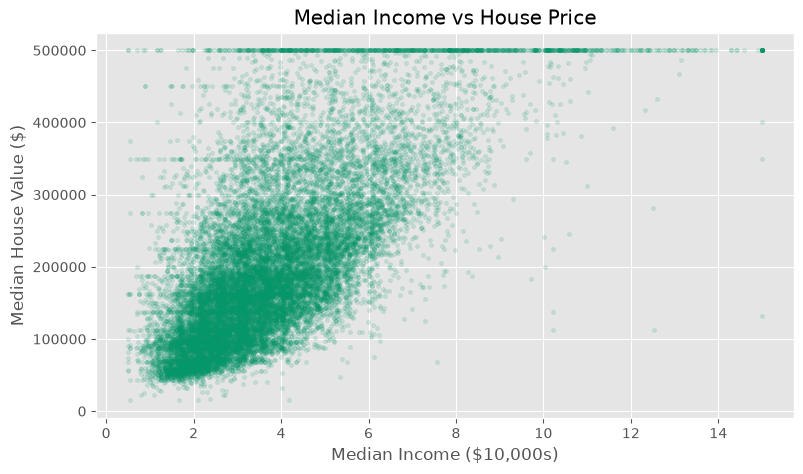

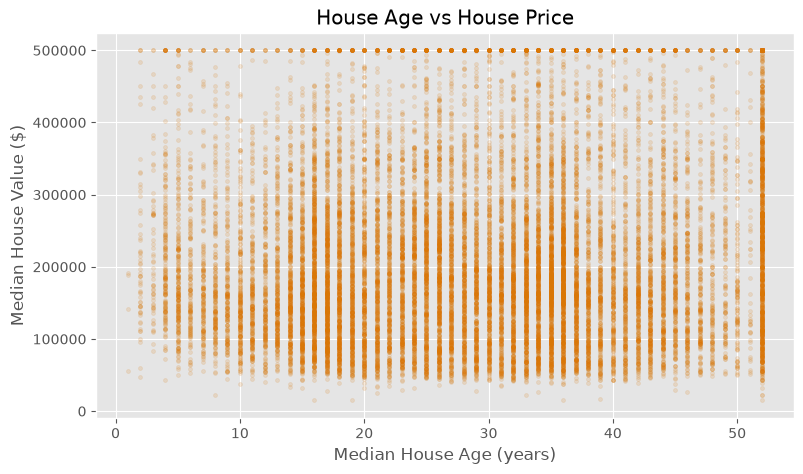

In [6]:
plt.figure(figsize=(9, 5))
plt.hist(df["MedHouseVal"] * 100000, bins=50, color="#2563eb", edgecolor="white")
plt.title("House Price Distribution (California)")
plt.xlabel("Median House Value ($)"); plt.ylabel("Number of blocks"); plt.show()

plt.figure(figsize=(9, 5))
plt.scatter(df["MedInc"], df["MedHouseVal"] * 100000, alpha=0.15, s=8, color="#059669")
plt.title("Median Income vs House Price")
plt.xlabel("Median Income ($10,000s)"); plt.ylabel("Median House Value ($)"); plt.show()

plt.figure(figsize=(9, 5))
plt.scatter(df["HouseAge"], df["MedHouseVal"] * 100000, alpha=0.15, s=8, color="#d97706")
plt.title("House Age vs House Price")
plt.xlabel("Median House Age (years)"); plt.ylabel("Median House Value ($)"); plt.show()

## 6. Where are the expensive houses? And what correlates with price?

On the map, expensive houses sit near the coast (San Francisco / Los Angeles).
The heatmap shows income is the strongest link with price.

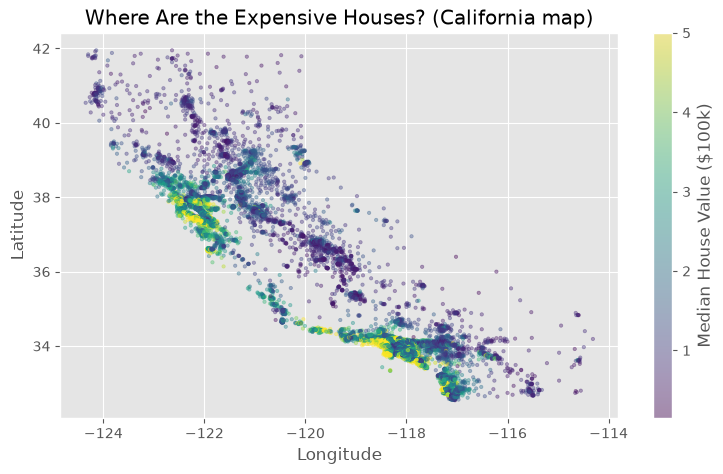

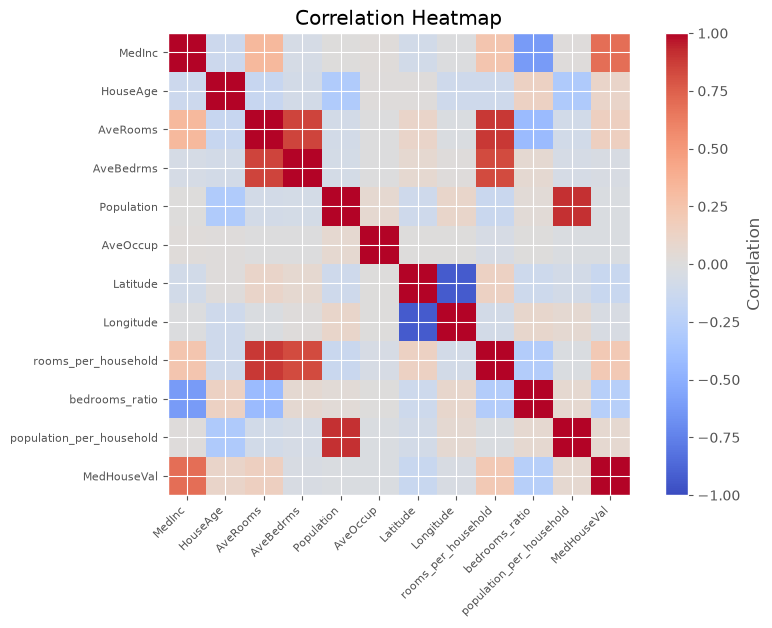

In [7]:
plt.figure(figsize=(9, 5))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], cmap="viridis", alpha=0.4, s=6)
plt.colorbar(sc, label="Median House Value ($100k)")
plt.title("Where Are the Expensive Houses? (California map)")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.show()

plt.figure(figsize=(9, 6))
corr = df[features + ["MedHouseVal"]].corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right", fontsize=8)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=8)
plt.title("Correlation Heatmap"); plt.show()

## 7. How good is the best model?

Random Forest was the best. I plot its predictions against the real prices —
points close to the red line are good guesses. Then I check which features it
used most: median income is by far the biggest one.

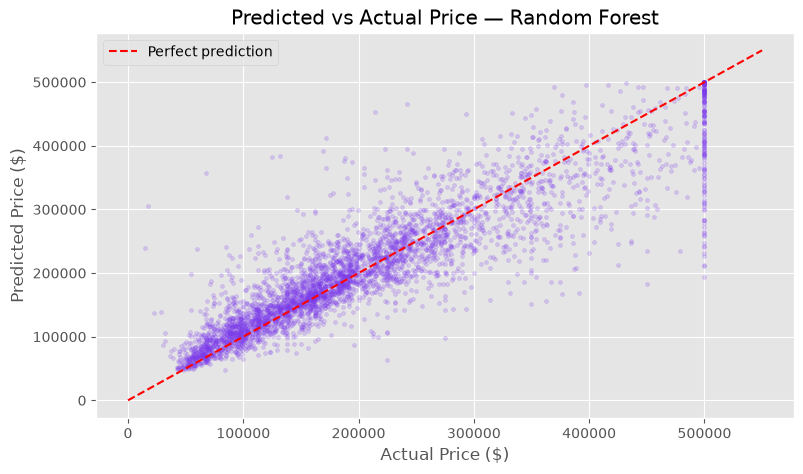

MedInc                      0.522
AveOccup                    0.126
Latitude                    0.082
Longitude                   0.082
HouseAge                    0.052
bedrooms_ratio              0.029
rooms_per_household         0.026
AveRooms                    0.025
AveBedrms                   0.022
population_per_household    0.018
Population                  0.016
dtype: float64


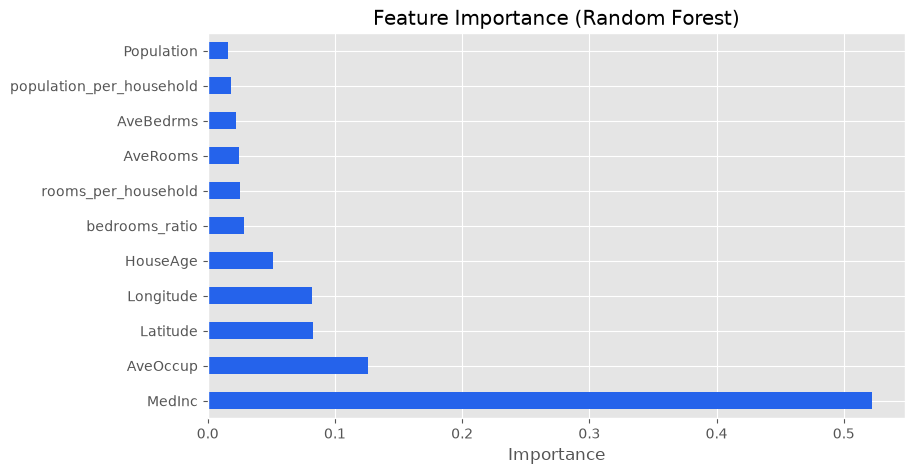

In [8]:
rf = models["Random Forest"]
y_pred_rf = rf.predict(X_test)
plt.figure(figsize=(9, 5))
plt.scatter(y_test * 100000, y_pred_rf * 100000, alpha=0.2, s=8, color="#7c3aed")
plt.plot([0, 550000], [0, 550000], "r--", label="Perfect prediction")
plt.title("Predicted vs Actual Price — Random Forest")
plt.xlabel("Actual Price ($)"); plt.ylabel("Predicted Price ($)")
plt.legend(); plt.show()

importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(importance.round(3))
importance.plot(kind="barh", color="#2563eb", figsize=(9, 5))
plt.title("Feature Importance (Random Forest)"); plt.xlabel("Importance"); plt.show()

## What I learned

- **Random Forest is the best here: R² 0.8065, MAE 0.3280 (≈ $32,800), RMSE 0.5035 (≈ $50,350).**
- Linear Regression only got R² 0.6535 — house prices are not a straight line.
- Gradient Boosting got R² 0.7788, close but a bit worse than Random Forest.
- The biggest factor is median income (importance 0.522), then how crowded a house is, then location (latitude/longitude).
- Limits: prices in this dataset are capped at $500,000, so very expensive houses all look the same. And this is California, USA data — not Bangladesh house prices, so I cannot use this model for Dhaka rent or flat prices directly.

Thanks for reading!